# INTEGRATES Building-Energy Calibration Challenge

## 00 - Challenge contract

Your task is to select a subset of the twelve available calibration parameters and replace the search strategy in the repository-root `calibration.py`. The search space contains uncertain operating schedules, controls, and tightly bounded heat-loss multipliers; audited values remain the fixed defaults. A two-regime model represents normally heated space and wings/floors operated at lower temperatures. Bolzano's legal heating season and dated exceptions are fixed challenge inputs, not calibration variables. Do not change the challenge-owned simulation, inputs, measurements, metrics, or export code.

Your file must define:

- `TEAM_NAME: str`
- `ALGORITHM_NAME: str`
- `calibrate(objective, parameter_space, budget, seed) -> dict[str, float]`

The returned dictionary must contain every supplied parameter name exactly once, with finite values inside the stated bounds. Call `objective(vector)` for a sequential evaluation. Methods that naturally propose a population may call `objective.evaluate_many(vectors)`; both interfaces use the same challenge-controlled local process pool, cache, validation, and evaluation budget. The vector order is the order of `parameter_space`. Every process runs on the laptop executing this notebook—there is no central simulation server or cross-laptop process pool. The official scored run uses buildings 01–03, years 2018–2019, January warm-up, and February/March scoring.


## 01 - Imports & Initialization

In [ ]:
import integrates_hackathon.notebook_workflow as workflow

# Official scoring configuration. Teams may temporarily shorten this list
# while developing, but final verification restores both official years.
CALIBRATION_YEARS = [2018] #[2018, 2019] # The challenge will be judged on February and March of 2018 and 2019; during development you could reduce to just one year for faster iterations.
EVALUATION_BUDGET = 6 #48  # The contest will be scored with budget of 48, but during development you could reduce this for faster iterations.
PARALLEL_WORKERS = 6  # Reduce this if the laptop has fewer available cores.

context = workflow.initialize_challenge(
    backend="pbe",
    # building_ids=("building_01", "building_02", "building_03"),
    building_ids=("building_02",), ## During development, you may wish to calibrate only one building for faster iterations --> recommend building_02
    calibration_years=tuple(CALIBRATION_YEARS),
    score_months=(2, 3),
    warmup_month=1,
    evaluation_budget=EVALUATION_BUDGET,
    parallel_workers=PARALLEL_WORKERS,
    seed=2026,
)
workflow.show_challenge_contract(context)


**Backend:** `pbe`  
**Simulation-evaluation budget:** `12` per building  
**Seed:** `2026`  
**Buildings:** `building_02`  
**Calibration years:** `[2018]`  
**Window:** January warm-up; February and March scored (no annualization)  
**Local simulation workers:** `6`  
**Example score:** `max(0, 100 - WAPE%)`, averaged equally across buildings.  
**Budget enforcement:** the organizer objective refuses any new candidate after the stated per-building budget.

,Required name,Type,Purpose
0,TEAM_NAME,str,Name shown in standardized results
1,ALGORITHM_NAME,str,Short algorithm description
2,calibrate,callable,Returns {parameter_name: best_value}


## 02 - Visualize Input Data

This section parses inputs for `building_01`, `building_02`, and `building_03` and displays the February/March bills and 2018–2019 weather. Fixed audited properties and the calibration bounds remain visible. Bolzano's legal heating season and dated exceptions are fixed inputs, not variables teams may change.


### Parsed anonymized building inputs

,building_id,building_use,construction_year,gross_floor_area_m2,conditioned_floor_area_m2,heated_volume_m3,floors_above_ground,total_height_m,footprint_area_m2,geometry_complete,source_status
0,building_02,school,1929,6090.6,4883.2,28934.9,3,19.5,1463.312579,True,


### EUBUCCO footprints at the shared anonymous centroid

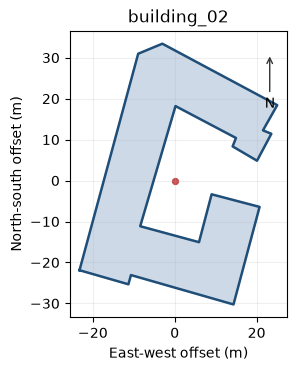

### Calibratable parameters

,building_id,parameter,lower,baseline,upper,unit,description
0,building_02,weekday_heating_hours,4.00,8.0,12.00,h/day,Active occupied-setpoint duration on weekdays
1,building_02,non_workday_heating_hours,0.00,2.0,4.00,h/day,Active occupied-setpoint duration on weekends ...
2,building_02,weekday_start_hour,5.00,7.0,9.00,hour,Start of active weekday heating
3,building_02,occupied_heating_setpoint_c,18.50,20.0,21.50,degC,Maintained setpoint during active occupied hours
4,building_02,night_setback_temperature_c,12.00,15.0,18.00,degC,Maintained setpoint outside active occupied ho...
5,building_02,outdoor_shutdown_temperature_c,12.00,15.0,18.00,degC,24-hour mean outdoor threshold switching activ...
6,building_02,normally_heated_area_fraction,0.60,0.8,1.00,fraction,Conditioned area following the normal rather t...
7,building_02,reduced_area_setpoint_c,12.00,15.0,17.00,degC,Active setpoint for wings/floors following the...
8,building_02,reduced_area_schedule_fraction,0.25,0.5,0.75,fraction,Reduced-regime active hours as a fraction of n...
9,building_02,air_exchange_multiplier,0.70,1.0,1.30,multiplier,Multiplier applied to audited/default infiltra...


### Fixed legal heating permissions
Ordinary Bolzano operation is limited to 15 October–15 April, 05:00–23:00, at no more than 14 h/day. The dated exceptions below are fixed at 7 h/day; algorithms cannot create other out-of-season operation.

,year,start_date,end_date_inclusive,maximum_hours_per_day,calibratable
0,2019,2019-04-16,2019-05-26,7,False
1,2020,2020-10-01,2020-10-14,7,False
2,2021,2021-04-16,2021-04-22,7,False
3,2021,2021-10-08,2021-10-14,7,False


### Selected February/March heating consumption (converted to kWh)
Combined heating and DHW bills minus each year's June–August average, which is taken as the monthly DHW load.

,building_id,year,consumption_kwh,consumption_kwh_m2_gfa,source_unit,end_use_scope
0,building_02,2018,154040.973333,25.291593,Smc,heating_only


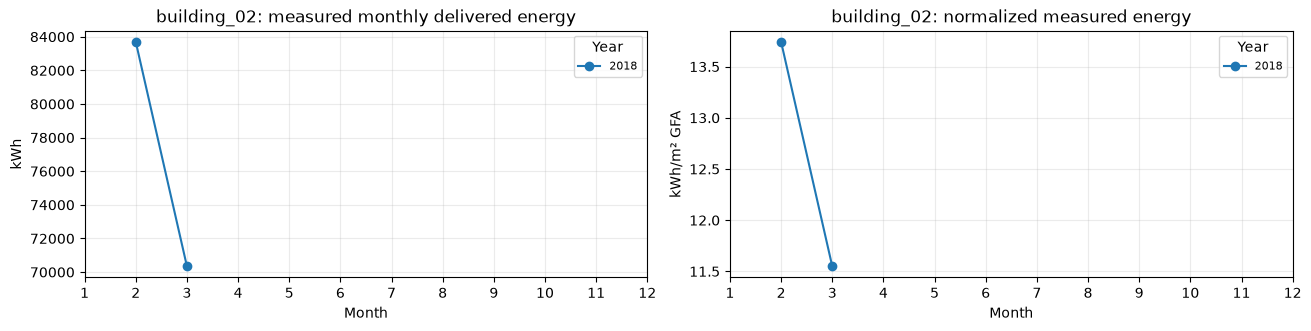

### Weather summary
Monthly temperature and heating-degree-day summaries calculated from the organizer-provided AMY EPW files for every reported consumption year.

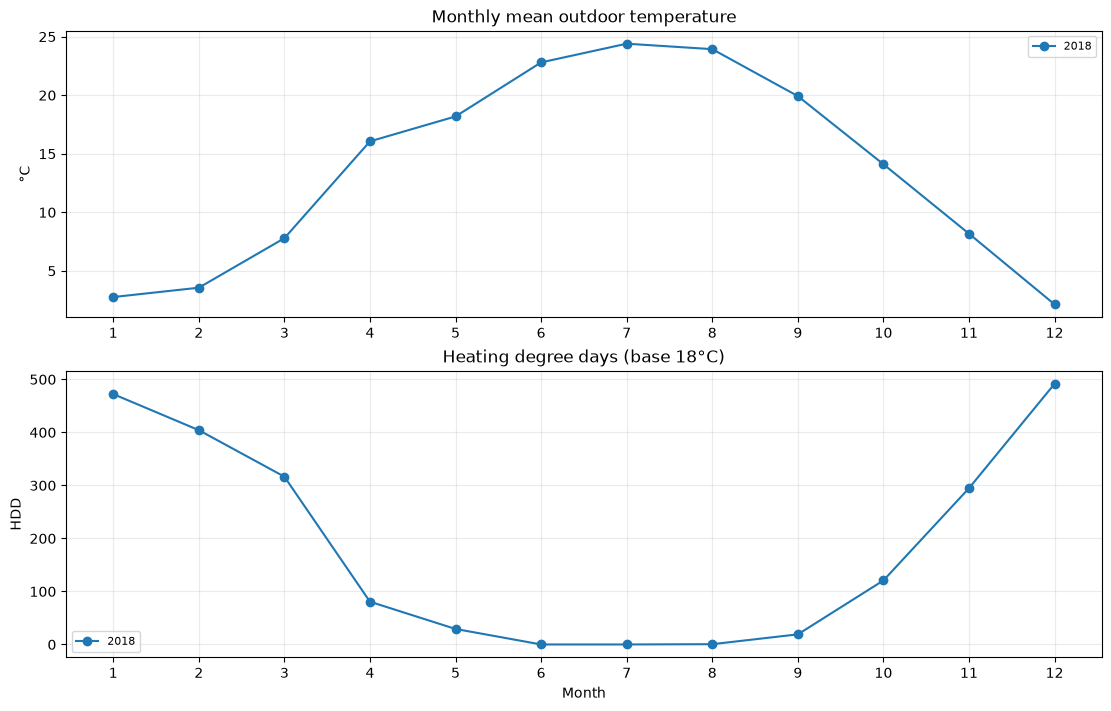

In [2]:
input_views = workflow.show_input_data(context)

## 03 - Load Baseline Energy Simulation

The notebook loads organizer-precomputed exact-window baseline results. Each selected year simulates every hour of January, February, and March; January is thermal warm-up and is discarded. Only February and March are compared with bills, with no annualization. Challengers do not rerun the baseline.

### Organizer-provided baseline results

,building_id,measured_months,measured_kwh,baseline_kwh
0,building_02,2,154040.973333,383736.854027


### Baseline monthly comparison

,team_name,algorithm_name,building_id,year,month,gross_floor_area_m2,actual_kwh,baseline_kwh,calibrated_kwh,actual_kwh_m2_gfa,baseline_kwh_m2_gfa,calibrated_kwh_m2_gfa,baseline_error_pct,calibrated_error_pct
0,,,building_02,2018,2,6090.6,83695.126667,197504.588813,None,13.741688,32.427772,None,135.98099,None
1,,,building_02,2018,3,6090.6,70345.846667,186232.265214,None,11.549904,30.576998,None,164.73811,None


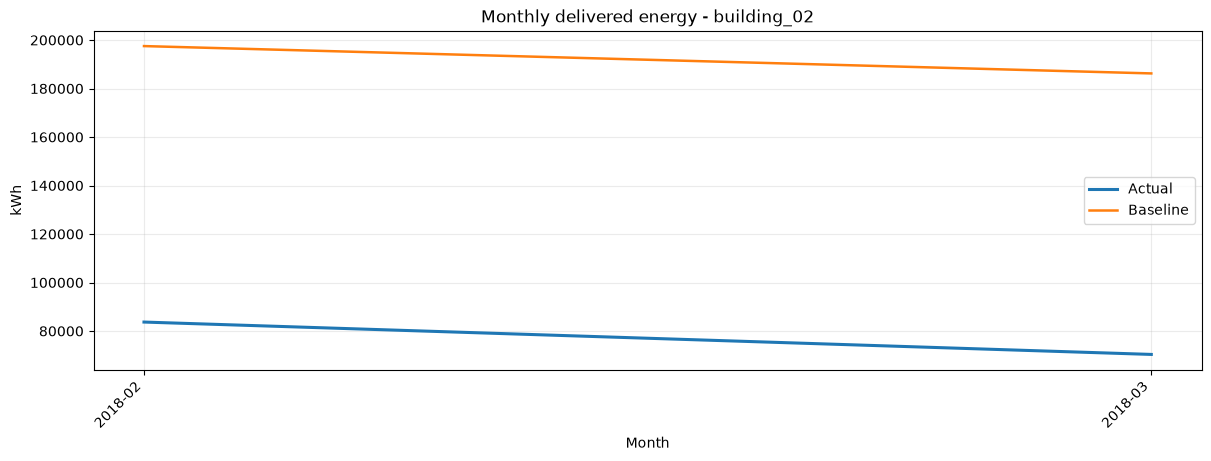

In [3]:
baseline = workflow.load_baseline(context)
baseline_results = workflow.show_baseline_results(context, baseline)

## 04 - Run Calibration

This section imports and runs the repository-root `calibration.py`. The shipped starter evaluates the default vector once and returns it unchanged, so its calibrated score exactly matches the baseline until participants replace the passthrough with a search strategy. Each laptop creates its own local worker pool; no simulations or data leave that computer. Independent weather years run in separate processes. Participant methods may use the optional `objective.evaluate_many(vectors)` interface when they can propose candidates together. Before each exact-window task, the parent process prints the building, scored month/year, and calibration-set counter.

The workflow passes `parameter_space`, `budget`, and `seed` into `calibration.py`. Each item in `parameter_space` provides `.name`, `.lower`, `.upper`, and `.default`; participant code should read these values rather than duplicate bounds or assume a particular budget. Teams may use larger local budgets while developing, but final verification runs their unchanged `calibration.py` in a clean challenge copy with the official budget, buildings, years, months, seed, and parameter contract. The objective stops with an error if code requests more than the permitted number of new candidates.

A submission returns one scalar value per active parameter and building. That same value is applied to every scored month and year. Keys containing special months/years, nested schedules, and extra return keys are rejected. Final verification transfers `calibration.py` plus the active-parameter selection recorded in the standardized JSON; edits to simulation, inputs, scoring, or notebook files do not accompany a submission.


In [4]:
### Calibratable parameters ###
# Replace None with an in-range numeric starting value to activate a parameter.
# None holds that parameter at the organizer default shown in its comment.
calibratable_params_init = {
    "weekday_heating_hours": 8, # active occupied-setpoint hours per weekday; default 8; simulator rounds to a whole hour ## allowable range [4,12]
    "non_workday_heating_hours": 2, # active hours on weekends/public holidays; default 2; simulator rounds to a whole hour ## allowable range [0,4]
    "weekday_start_hour": 7, # start of active weekday heating; default 7; simulator rounds to a whole hour ## allowable range [5,9]
    "occupied_heating_setpoint_c": 20.0, # normal-regime setpoint during active hours; default 20 ## allowable range [18.5,21.5]
    "night_setback_temperature_c": 15.0, # maintained setpoint outside active hours, with energy counted; default 15 ## allowable range [12,18]
    "outdoor_shutdown_temperature_c": 15.0, # 24-hour mean outdoor threshold switching active heating to setback; default 15 ## allowable range [12,18]
    "normally_heated_area_fraction": 0.8, # conditioned area following normal rather than reduced regime; default 0.8 ## allowable range [0.6,1.0]
    "reduced_area_setpoint_c": 15.0, # active setpoint for reduced-regime areas; default 15 ## allowable range [12,17]
    "reduced_area_schedule_fraction": 0.5, # reduced active hours divided by normal active hours; default 0.5 ## allowable range [0.25,0.75]
    "air_exchange_multiplier": 1.0, # multiplier on audited/default infiltration and ventilation; default 1.0 ## allowable range [0.7,1.3]
    "opaque_envelope_u_value_multiplier": 1.0, # common audited wall/roof/floor U-value multiplier; default 1.0 ## allowable range [0.9,1.1]
    "window_u_value_multiplier": 1.0, # audited window U-value multiplier; default 1.0 ## allowable range [0.9,1.1]
}

# Organizer-owned assertions stop the run if keys change or if any activated
# starting value is non-numeric or outside its organizer-owned range.
context = workflow.configure_parameter_contract(
    context, calibratable_params_init
)

# experiments.py (repository root) is our own experiment runner, not organizer code.
# load_or_run_calibration() replaces workflow.run_calibration(): if outputs/runs/
# holds a valid result of this exact experiment, it is loaded instead of rerun.
# algorithm=None runs the method in calibration.py; a name such as "tpe" runs
# that method from alternative_algorithms.py instead.
import sys

from integrates_hackathon.submission_api import repository_root

sys.path.insert(0, str(repository_root()))
import experiments

calibration_run = experiments.load_or_run_calibration(context, algorithm=None)
calibrated_parameters = workflow.show_calibration_results(context, calibration_run)

Parameter rule check passed: 12/12 calibratable parameters activated (weekday_heating_hours, non_workday_heating_hours, weekday_start_hour, occupied_heating_setpoint_c, night_setback_temperature_c, outdoor_shutdown_temperature_c, normally_heated_area_fraction, reduced_area_setpoint_c, reduced_area_schedule_fraction, air_exchange_multiplier, opaque_envelope_u_value_multiplier, window_u_value_multiplier).
Shared active-parameter contract applied to every building and every scored month/year; month-specific and year-specific parameter keys are not accepted.
Running ard_bayesian_optimisation__budget12__2018__b02__w6 (no saved result).
Now running building_02, February 2018, calibration set 1 of 12
Now running building_02, March 2018, calibration set 1 of 12
Now running building_02, February 2018, calibration set 2 of 12
Now running building_02, March 2018, calibration set 2 of 12
Now running building_02, February 2018, calibration set 3 of 12
Now running building_02, March 2018, calibratio

### Calibration returned by Calibra
Algorithm: **ard_bayesian_optimisation**

,team_name,algorithm_name,building_id,parameter,lower,baseline,calibrated,upper,unit
0,Calibra,ard_bayesian_optimisation,building_02,weekday_heating_hours,4.00,8.0,4.000000,12.00,h/day
1,Calibra,ard_bayesian_optimisation,building_02,non_workday_heating_hours,0.00,2.0,0.000000,4.00,h/day
2,Calibra,ard_bayesian_optimisation,building_02,weekday_start_hour,5.00,7.0,5.187058,9.00,hour
3,Calibra,ard_bayesian_optimisation,building_02,occupied_heating_setpoint_c,18.50,20.0,21.500000,21.50,degC
4,Calibra,ard_bayesian_optimisation,building_02,night_setback_temperature_c,12.00,15.0,14.862986,18.00,degC
5,Calibra,ard_bayesian_optimisation,building_02,outdoor_shutdown_temperature_c,12.00,15.0,17.978794,18.00,degC
6,Calibra,ard_bayesian_optimisation,building_02,normally_heated_area_fraction,0.60,0.8,0.600000,1.00,fraction
7,Calibra,ard_bayesian_optimisation,building_02,reduced_area_setpoint_c,12.00,15.0,13.675280,17.00,degC
8,Calibra,ard_bayesian_optimisation,building_02,reduced_area_schedule_fraction,0.25,0.5,0.694537,0.75,fraction
9,Calibra,ard_bayesian_optimisation,building_02,air_exchange_multiplier,0.70,1.0,1.184250,1.30,multiplier


## 05 - Validate & Compare Results

The organizer-owned workflow validates every returned value and compares the independently rerun calibrated simulation with the baseline and measured monthly consumption.

### Actual, baseline, and independently rerun calibrated results

,team_name,algorithm_name,building_id,year,month,gross_floor_area_m2,actual_kwh,baseline_kwh,calibrated_kwh,actual_kwh_m2_gfa,baseline_kwh_m2_gfa,calibrated_kwh_m2_gfa,baseline_error_pct,calibrated_error_pct
0,Calibra,ard_bayesian_optimisation,building_02,2018,2,6090.6,83695.126667,197504.588813,105750.055721,13.741688,32.427772,17.362831,135.98099,26.351509
1,Calibra,ard_bayesian_optimisation,building_02,2018,3,6090.6,70345.846667,186232.265214,90575.950742,11.549904,30.576998,14.871433,164.73811,28.758065


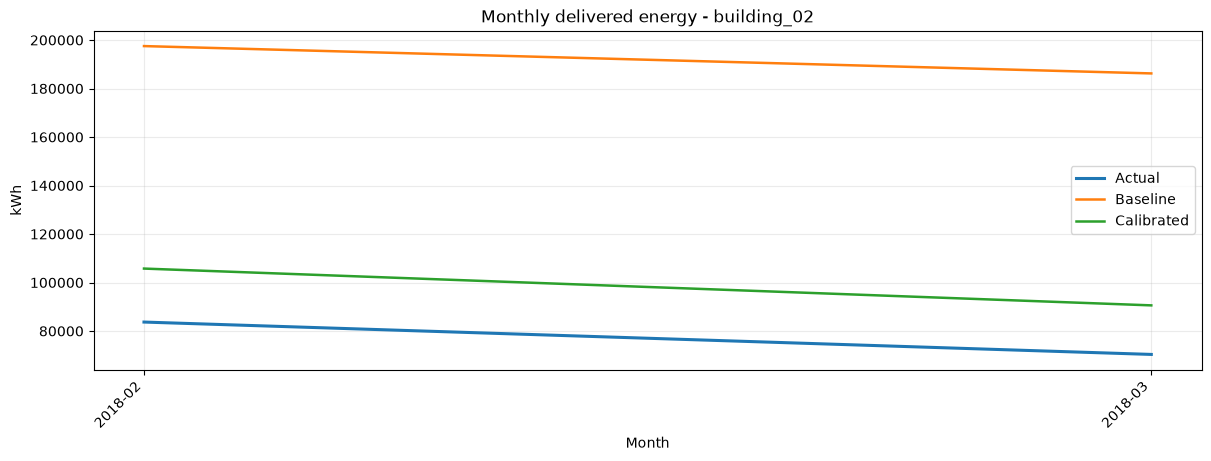

In [5]:
comparison_results = workflow.show_calibrated_comparison(
    context, baseline, calibration_run
)

## 06 - Scoring

WAPE is calculated only from the February/March bills in `CALIBRATION_YEARS`; nothing is annualized. The example positive score is `max(0, 100 - WAPE%)`. Each building is weighted equally so a large building cannot dominate. Baseline score, improvement, CV(RMSE), NMBE, and evaluation count remain visible for interpretation and possible tie-breaking.

## Example overall score: **72.55 / 100**
The example uses `100 - WAPE%` with a zero floor and weights each building equally. CVRMSE and NMBE are reported as diagnostics and possible tie-breakers.

,team_name,building_id,baseline_score,calibrated_score,improvement_points,baseline_weighted_absolute_percentage_error,calibrated_weighted_absolute_percentage_error,calibrated_cv_rmse_pct,calibrated_nmbe_pct,evaluations,runtime_seconds
0,Calibra,building_02,0.0,72.54949,72.54949,149.113496,27.45051,27.47606,27.45051,12,130.885095


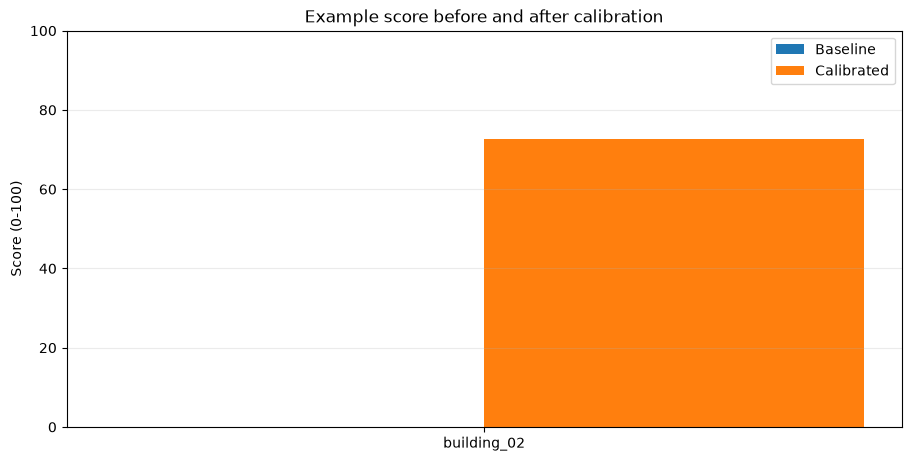

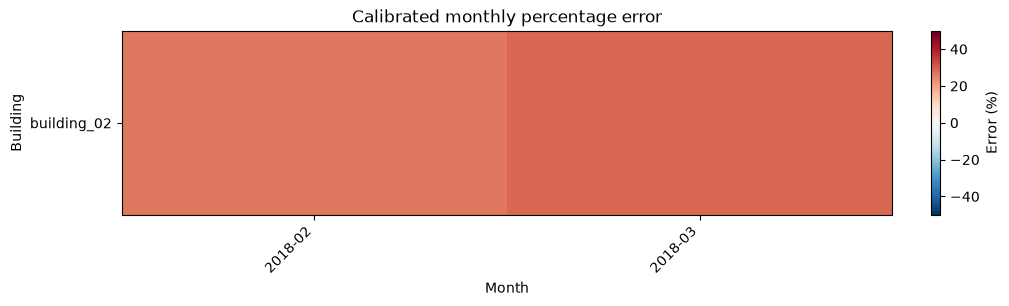

In [6]:
score_report = workflow.score_and_visualize(context, baseline, calibration_run)

## 07 - Export

Every team produces the same four artifacts: a one-row-per-building summary, a one-row-per-building-month comparison, an organizer-recorded trace of every unique budget-charged evaluation, and a machine-readable JSON result containing metadata, scores, active parameter selection, the calibration.py SHA-256 hash, and calibrated parameters.

In [7]:
exported_paths = workflow.export_standardized_results(context, calibration_run, score_report)
workflow.show_exported_results(exported_paths)

### Standardized result files
- **summary:** `D:\Private\hack2026\integrates\outputs\calibra\summary.csv`
- **monthly:** `D:\Private\hack2026\integrates\outputs\calibra\monthly_results.csv`
- **evaluation_trace:** `D:\Private\hack2026\integrates\outputs\calibra\evaluation_trace.csv`
- **json:** `D:\Private\hack2026\integrates\outputs\calibra\submission_result.json`

## 08 - Algorithm comparison (development only)

Section 07 always exports to `outputs/<team-name>/`, so every run overwrites the previous one. This section keeps each run and compares them from the exported files only; nothing is simulated here. It uses the same code and the same `outputs/runs/` folder as the command-line runner `experiments.py`, so runs made there (for example on the cluster) appear here too, and the other way round.

**Workflow**
1. Run Sections 01-07, then **08a**, which saves the export to `outputs/runs/<run-id>/`. To try another method, set `algorithm="..."` in Section 04 to a name registered in `alternative_algorithms.py`.
2. If the same experiment is already saved, Section 04 loads it instead of rerunning and says so. "Same" means the same algorithm, buildings, years, budget, worker count, seed and active parameters, and unchanged behaviour of the code that algorithm uses; see the docstring of `experiments.py`. If something relevant changed, Section 04 names it and reruns, and 08a keeps the old result in `outputs/runs/_superseded/`.
3. Run **08b** to compare saved runs.

### 08a - Save this run

In [8]:
saved_run_dir = experiments.save_calibration(context, calibration_run, score_report, exported_paths)


Saved to D:\Private\hack2026\integrates\outputs\runs\ard_bayesian_optimisation__budget12__2018__b02__w6


### 08b - Compare saved runs

`RUNS_TO_COMPARE` lists texts; every saved run whose folder name contains one of them is compared. `None` compares every saved run. Only compare runs with the same buildings and years when judging scores; the folder name shows both.

### Calibrated score (higher is better)

building_id,name,building_01,building_02,building_03,OVERALL
run,,,,,
all_12__ard_bayesian_optimisation__budget48__2018+2019__b01+b02+b03__w12__afef0.5,all_12,96.44,99.41,96.81,97.55
all_12__ard_bayesian_optimisation__budget48__2018+2019__b01+b02+b03__w12__afef0.75,all_12,96.47,98.83,96.28,97.19
all_12__ard_bayesian_optimisation__budget48__2018+2019__b01+b02+b03__w12__afef1,all_12,96.03,99.05,96.02,97.03
all_12__ard_bayesian_optimisation__budget48__2018+2019__b01+b02+b03__w12,all_12,96.03,99.05,96.02,97.03
all_12__ard_bayesian_optimisation__budget48__2018+2019__b01+b02+b03__w12__aif1,all_12,96.03,99.05,96.02,97.03
all_12__ard_bayesian_optimisation__budget48__2018+2019__b01+b02+b03__w12__ar0.5,all_12,96.03,99.05,96.02,97.03
all_12__ard_bayesian_optimisation__budget48__2018+2019__b01+b02+b03__w12__aif0.75,all_12,96.03,99.05,96.02,97.03
all_12__ard_bayesian_optimisation__budget48__2018+2019__b01+b02+b03__w12__aif0.5,all_12,96.03,99.05,96.02,97.03
all_12__ard_bayesian_optimisation__budget48__2018+2019__b01+b02+b03__w12__ar0.25,all_12,96.03,99.05,96.02,97.03


### Details

name  \
building_id run                                                          
building_01 all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__bayesian_optimization__budget48__2018+2...  all_12   
building_02 all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__bayesian_optimization__budget48__2018+2...  all_12   
building_03 all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12   
            all_12__ard_bayesian_optimisation__budget48__20...  all_12

### Best parameters found

weekday_heating_hours  \
building_id run                                                                         
building_01 all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  7.331   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.034   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__bayesian_optimization__budget48__2018+2...                  4.000   
building_02 all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.035   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__bayesian_optimization__budget48__2018+2...                  4.000   
building_03 all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20...                  4.000   
            all_12__ard_bayesian_optimisation__budget48__20

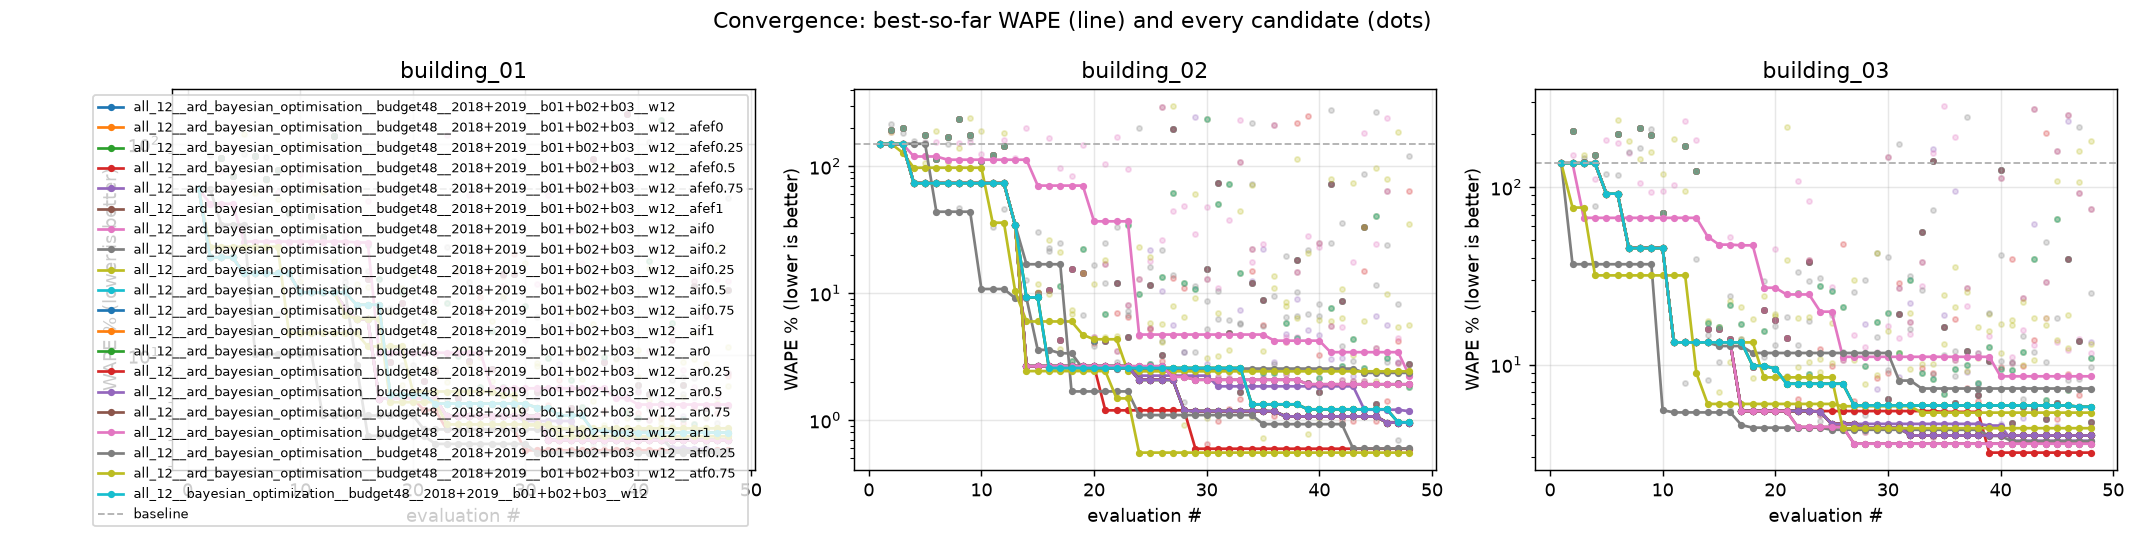

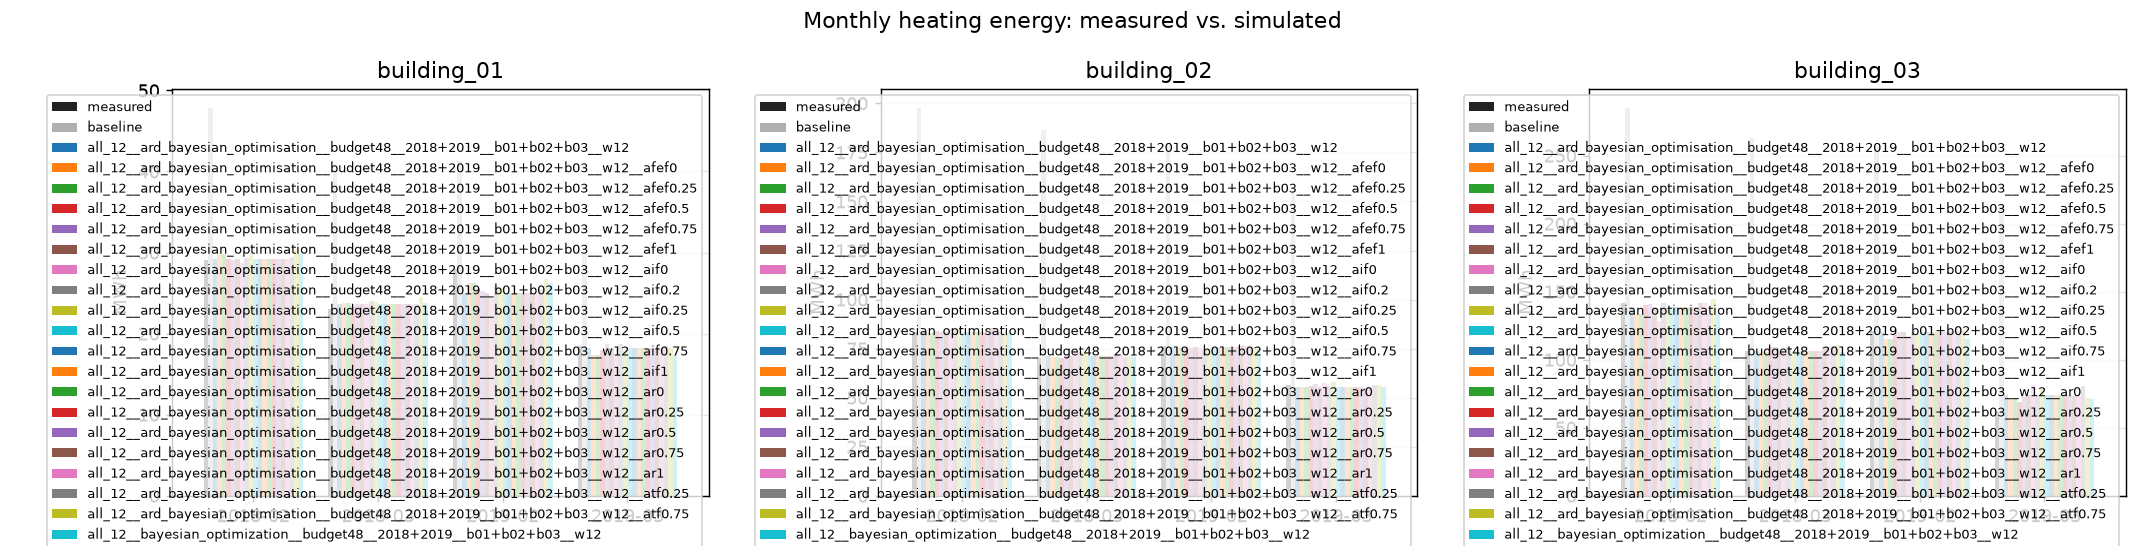

In [9]:
from IPython.display import Image, Markdown, display

RUNS_TO_COMPARE = ["all_12__ard_bayesian_optimisation__budget48", "all_12__bayesian_optimization__budget48"]  # None: every saved run

comparison = experiments.compare(runs=RUNS_TO_COMPARE, all_runs=RUNS_TO_COMPARE is None)
if comparison is None:
    raise FileNotFoundError("No saved run matches. Run Sections 04-07 and 08a first.")
if not comparison["comparable"]:
    display(Markdown("**These runs cover different buildings or years, so their OVERALL scores are not comparable.**"))

display(Markdown("### Calibrated score (higher is better)"))
display(comparison["scores"].style.format("{:.2f}", subset=comparison["scores"].columns[1:], na_rep="-"))
display(Markdown("### Details"))
display(comparison["details"].round(2))
display(Markdown("### Best parameters found"))
display(comparison["parameters"].round(3))
for file in comparison["files"]:
    if file.suffix == ".png":
        display(Image(filename=str(file)))
